## Способы реализации линейной регрессии

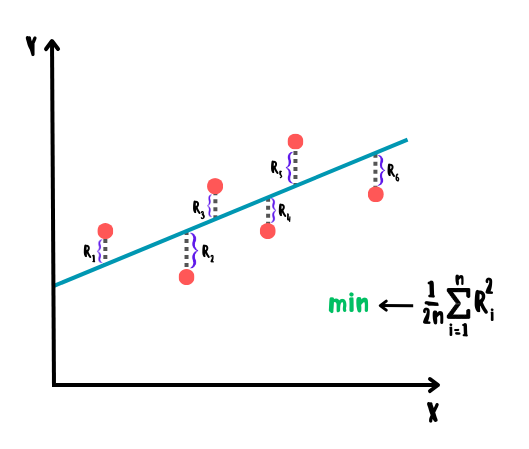

### Нормальное (прямое/матричное) уравнение


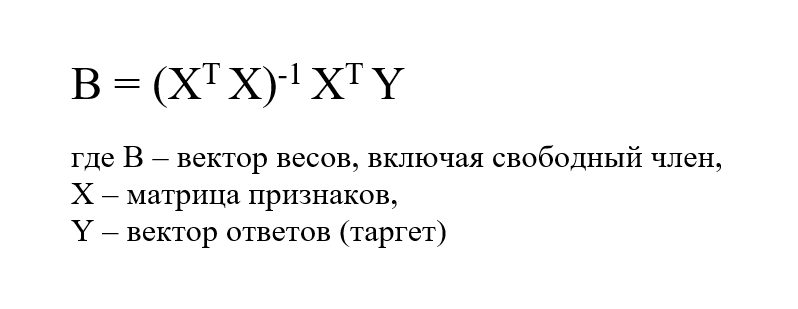

Недостатки уравнения:
- Использует в качестве измерения ошибки только MSE
- Сложность нахождения обратной матрицы - O(n3)

### Градиентный спуск 
метод минимизации функции потерь, при котором происходит итеративный сдвиг весов на антиградиент этой функции с небольшим весом

Задание 1: Найдите минимум функции

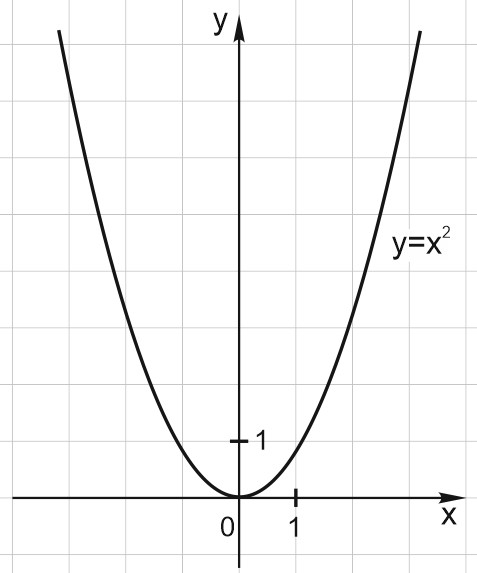

Но не всегда можно найти точку минимума с помощью производной даже у самых простейших функций. Пример:

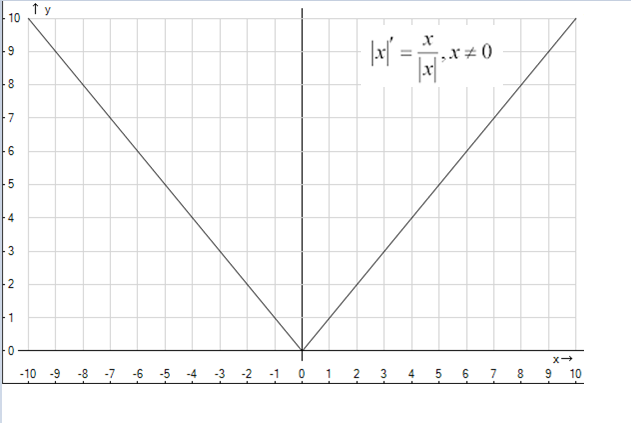

Иллюстрация градиентного спуска

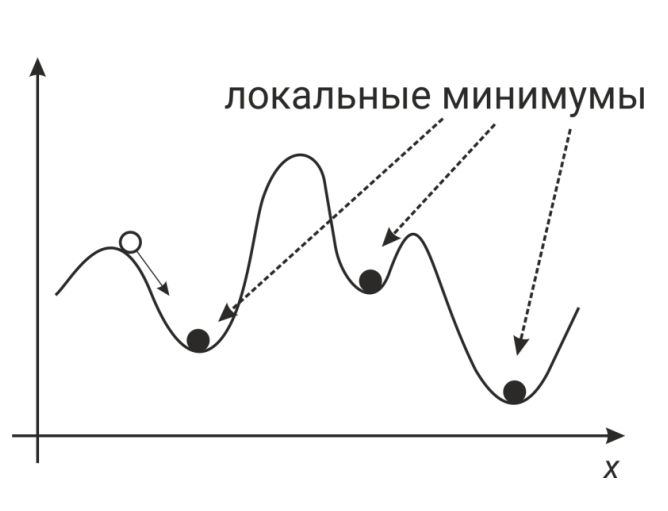

Пример 2: Найти минимум функции f(x)=x6+x5+x2+x

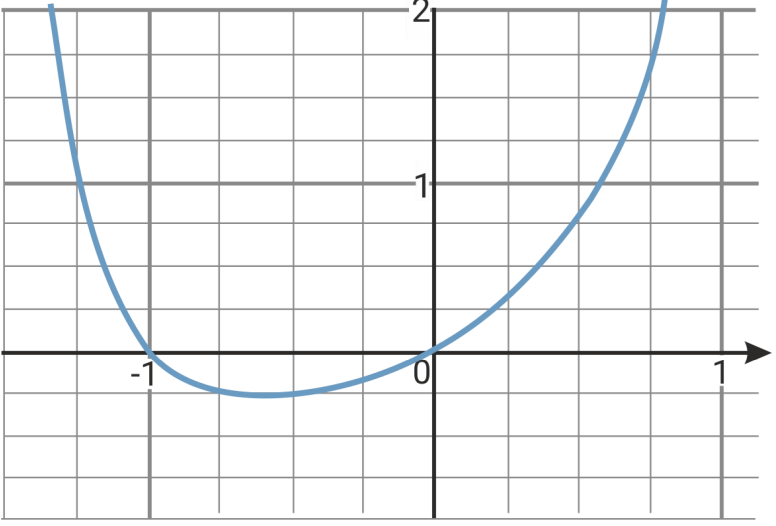

In [2]:
import pandas as pd

In [13]:
result = pd.DataFrame({
    'a_n' : [],
    'f`(a_n)' : [],
    'f(a_n)' : []
})

In [7]:
def function(x):
    return x ** 6 + x ** 5 + x ** 2 + x

In [4]:
def derivative(x):
    return 6 * x ** 5 + 5 * x ** 4 + 2 * x + 1

In [6]:
# пусть h = 0.1

def gradient_descent(a):
    a = a - derivative(a) * 0.1
    return a, derivative(a)

In [ ]:
# Начнем с а_0 = 0
a_n = 0
for i in range(15):
    data = {}
    a_n, der_a = gradient_descent(a_n)
    f_a = function(a_n)
    data = {
        'a_n' : a_n,
        'f`(a_n)' : der_a,
        'f(a_n)' : f_a
    }
    result.loc[len(result)] = data
    

In [15]:
result

,a_n,f`(a_n),f(a_n)
0,-0.100000,0.800440,-0.090009
1,-0.180044,0.644031,-0.147783
2,-0.244447,0.523722,-0.185352
3,-0.296819,0.431348,-0.210338
4,-0.339954,0.359630,-0.227382
5,-0.375917,0.302972,-0.239288
6,-0.406214,0.257350,-0.247772
7,-0.431949,0.219940,-0.253911
8,-0.453943,0.188773,-0.258404
9,-0.472820,0.162467,-0.261719


Замечания:
- производная (по модулю) уменьшается и приближается к 0;
- значения функции уменьшаются;
- точка a_n приближается к истинной точке минимума;
- расстояние между соседними точками a_n уменьшается. 

#### Недостатки градиентного спуска

1. Выбор начальной точки - неудачный выбор старта может привести к скатыванию градиента в локальный минимум

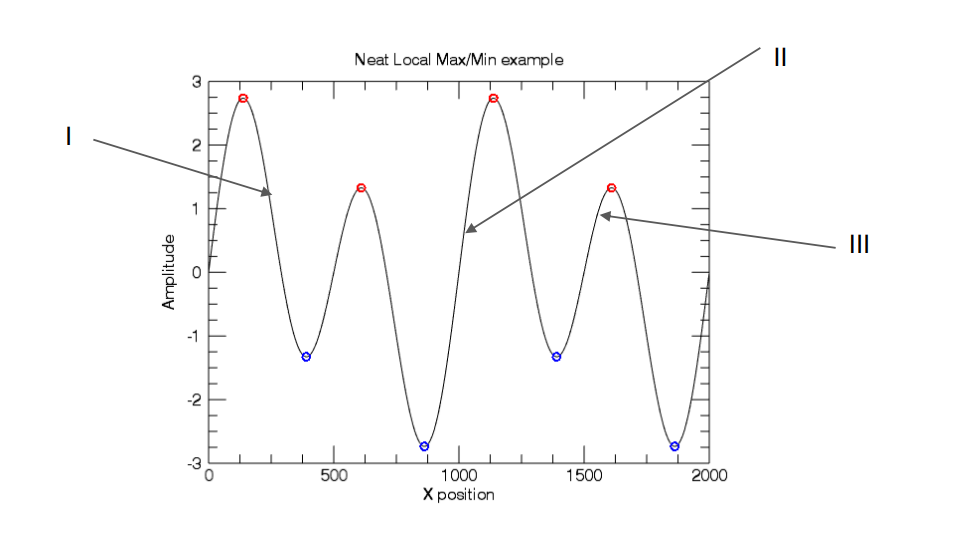

2. Слишком маленький шаг h - приводит к скатыванию в локальный минимум

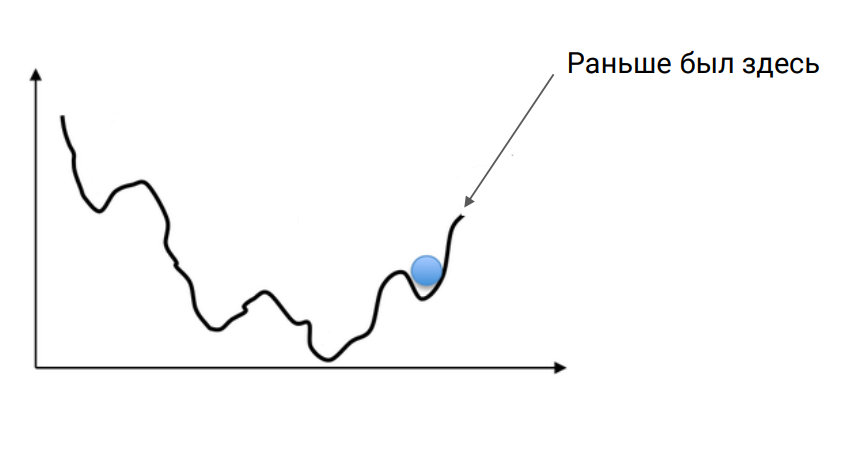

3. Слишком большой шаг h - приводит к "перешагиванию" минимумов

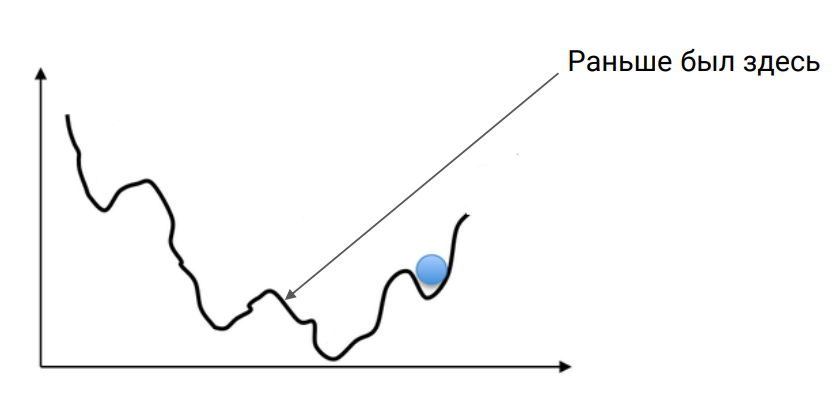

4. Неверный выбор шага - приводит к зацикливанию 

5. Затухание градиента - спуск плохо себя показывает на "прямых" участках функции. Как результат - движения в сторону минимума не происходит

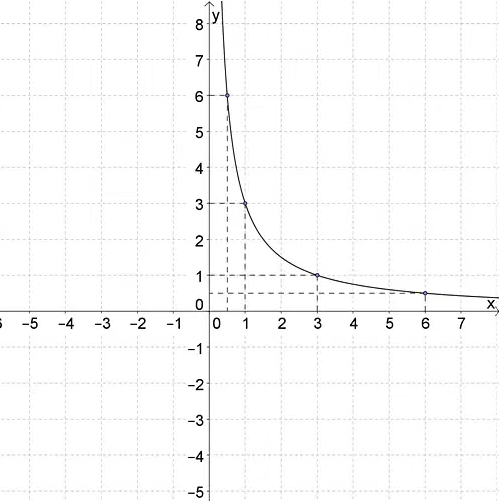

6. Взрыв градиента - движение с большим шагом, значение производной в точке велико

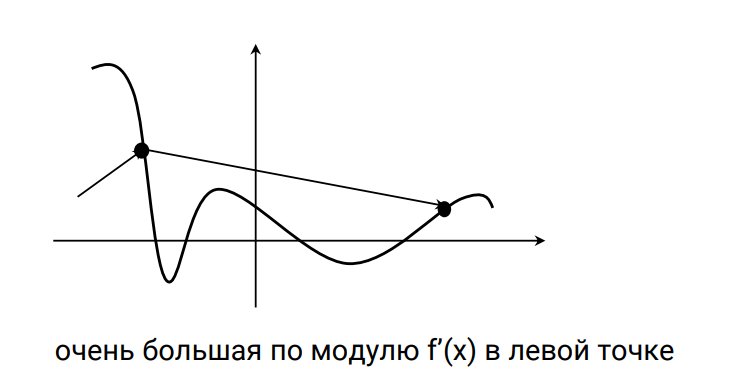

#### Преимущества градиентного спуска

- Других общих методов нахождения точек минимума нет
- Проблемы с выбором h вполне решаемы: можно изменять величину h на каждой итерации. На первых итерациях h можетбыть достаточно большим, и потом плавно уменьшаться.
- Метод может работать, даже когда производная неизвестна (численное дифференцирование)

### Градиентный спуск для функции многих переменных

Для нахождения минимума ФМП находятся частные производные по всем аргументам. Если точка (a1,a2, ..., an) является точкой локального минимума ФМП f(x1,x2, ..., an), то все частные производные равны нулю в этой точке.


Задание: найдите минимум функции f(x, y) = x^2 + y^2

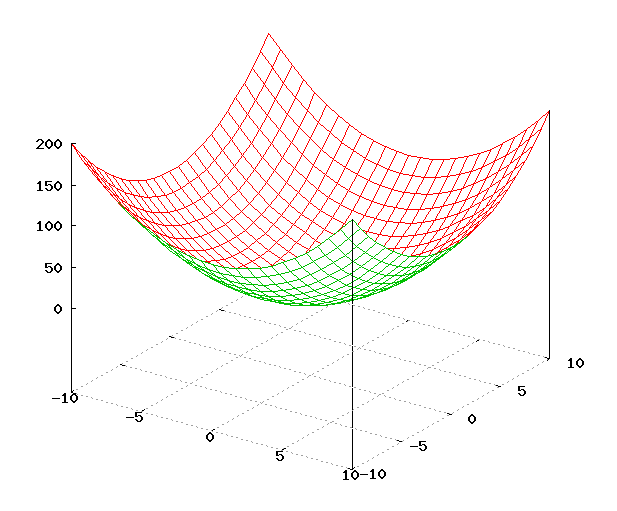

Нахождение минимума с помощью градиентного спуска

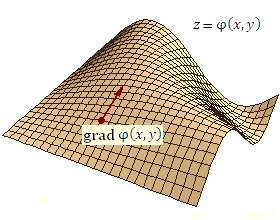

Градиент (как вектор) показывает направление наибольшего возрастания функции. Поэтому для задачи нахождения минимума необходимо двигаться в обратном направлении - в сторону антиградиента

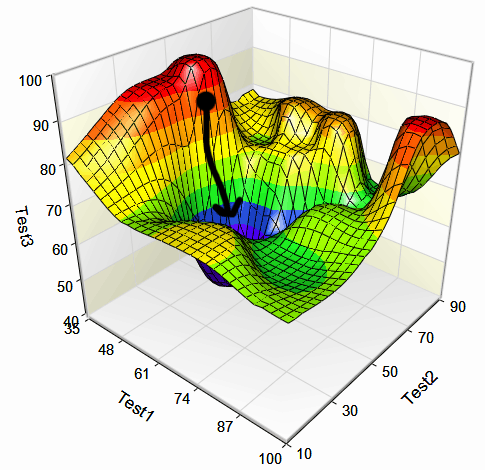

Позиция градиента на каждом шаге равна:

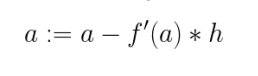
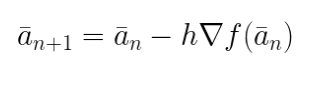